In [1]:
!pip install -q datasets indic-nlp-library pandas numpy tqdm sentencepiece tokenizers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 99.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.1/121.1 kB 10.9 MB/s eta 0:00:00


In [2]:
from datasets import load_dataset
from indicnlp.tokenize import sentence_tokenize

from tokenizers import Tokenizer
from tokenizers.models import BPE, WordPiece
from tokenizers.trainers import BpeTrainer, WordPieceTrainer
from tokenizers.pre_tokenizers import Whitespace

from tqdm import tqdm
import pandas as pd
import numpy as np
import random
import os

In [3]:
from huggingface_hub import login

login()

In [4]:
dataset_dict = load_dataset(
    "ai4bharat/IndicCorpV2",
    streaming=True
)

languages = list(dataset_dict.keys())

print("Number of languages:", len(languages))
print("Available languages:")
print(languages)

README.md:   0%|          | 0.00/4.01k [00:00<?, ?B/s]

Number of languages: 23
Available languages:
['asm_Beng', 'ben_Beng', 'brx_Deva', 'doi_Deva', 'gom_Deva', 'guj_Gujr', 'hin_Deva', 'kan_Knda', 'kas_Arab', 'mai_Deva', 'mal_Mlym', 'mar_Deva', 'mni_Mtei', 'npi_Deva', 'ory_Orya', 'pan_Guru', 'san_Deva', 'snd_Deva', 'tam_Taml', 'tel_Telu', 'urd_Arab', 'khasi', 'santhali']


In [5]:
LANGUAGE = "hin_Deva"

dataset = dataset_dict[LANGUAGE]

print("Selected language:", LANGUAGE)
print("Dataset type:", type(dataset))

Selected language: hin_Deva
Dataset type: <class 'datasets.iterable_dataset.IterableDataset'>


In [6]:
dataset = dataset_dict["hin_Deva"]

In [7]:
for row in dataset:
    print("Available columns:", row.keys())
    print("\nSample paragraph:\n")
    print(row["text"][:2000])
    break

Available columns: dict_keys(['text'])

Sample paragraph:

लोगों को बिलों संबंधी सुविधा देना ही उनका काम


In [8]:
# %% [code]
TARGET_SENTENCES = 1_200_000

all_sentences = []

for row in tqdm(dataset, desc="Reading paragraphs"):

    text = row["text"]

    try:
        sentences = sentence_tokenize.sentence_split(
            text,
            lang="hi"
        )

        for sentence in sentences:
            sentence = sentence.strip()

            if len(sentence.split()) >= 3:
                all_sentences.append(sentence)

        if len(all_sentences) >= TARGET_SENTENCES:
            break

    except Exception:
        continue

print("Total sentences collected:", len(all_sentences))

Reading paragraphs: 763192it [00:34, 22205.23it/s]

Total sentences collected: 1200003


In [9]:
# %% [code]
all_sentences = list(dict.fromkeys(all_sentences))

print("Unique sentences:", len(all_sentences))

if len(all_sentences) >= 1_002_000:
    print("Enough sentences available.")
else:
    print("Warning: Not enough sentences.")

Unique sentences: 1193558
Enough sentences available.


In [10]:
# %% [code]
sentence_lengths = np.array([
    len(sentence.split())
    for sentence in all_sentences
])

print("Minimum Length :", sentence_lengths.min())
print("Maximum Length :", sentence_lengths.max())
print("Average Length :", round(sentence_lengths.mean(), 2))
print("Median Length  :", np.median(sentence_lengths))

Minimum Length : 3
Maximum Length : 1682
Average Length : 18.38
Median Length  : 16.0


In [11]:
# %% [code]
def stratified_sample(sentences, n, seed=42):

    random.seed(seed)

    lengths = np.array([
        len(sentence.split())
        for sentence in sentences
    ])

    bins = [0,5,10,15,20,30,40,60,100,np.inf]

    categories = pd.cut(lengths, bins=bins)

    df = pd.DataFrame({
        "sentence": sentences,
        "category": categories
    })

    sampled = []

    proportions = df["category"].value_counts(
        normalize=True,
        sort=False
    )

    for category, proportion in proportions.items():

        group = df[df["category"] == category]

        count = max(1, int(round(proportion * n)))
        count = min(count, len(group))

        sampled.append(
            group.sample(n=count, random_state=seed)
        )

    result = pd.concat(sampled)

    if len(result) > n:
        result = result.sample(n=n, random_state=seed)

    elif len(result) < n:

        remaining = df.drop(result.index)

        extra = remaining.sample(
            n=n-len(result),
            random_state=seed
        )

        result = pd.concat([result, extra])

    return result.sample(frac=1, random_state=seed)["sentence"].tolist()

In [12]:
# %% [code]
DEV_SIZE = 1000

dev_sentences = stratified_sample(
    all_sentences,
    DEV_SIZE,
    seed=42
)

print("Development Sentences :", len(dev_sentences))

Development Sentences : 1000


In [13]:
# %% [code]
dev_set = set(dev_sentences)

remaining_sentences = [
    s for s in all_sentences
    if s not in dev_set
]

TEST_SIZE = 1000

test_sentences = stratified_sample(
    remaining_sentences,
    TEST_SIZE,
    seed=123
)

print("Test Sentences :", len(test_sentences))

Test Sentences : 1000


In [14]:
# %% [code]
special = set(dev_sentences) | set(test_sentences)

training_pool = [
    s for s in all_sentences
    if s not in special
]

random.seed(42)
random.shuffle(training_pool)

train_sentences = training_pool[:1_000_000]

print("Training :", len(train_sentences))
print("Development :", len(dev_sentences))
print("Test :", len(test_sentences))

Training : 1000000
Development : 1000
Test : 1000


In [15]:
# %% [code]
def add_sentence_tokens(sentence, n):

    words = sentence.split()

    start_tokens = ["<s>"] * (n - 1)

    return start_tokens + words + ["</s>"]


for n in [1, 2, 3, 4]:

    tokens = add_sentence_tokens(
        train_sentences[0],
        n
    )

    print(f"{n}-gram Example:")
    print(tokens[:12])
    print()

1-gram Example:
['अब', 'जगह-जगह', 'से', 'जर्जर', 'हो', 'चुकी', 'है।', '</s>']

2-gram Example:
['<s>', 'अब', 'जगह-जगह', 'से', 'जर्जर', 'हो', 'चुकी', 'है।', '</s>']

3-gram Example:
['<s>', '<s>', 'अब', 'जगह-जगह', 'से', 'जर्जर', 'हो', 'चुकी', 'है।', '</s>']

4-gram Example:
['<s>', '<s>', '<s>', 'अब', 'जगह-जगह', 'से', 'जर्जर', 'हो', 'चुकी', 'है।', '</s>']



In [16]:
# %% [code]
from collections import Counter

word_counts = Counter()

for sentence in tqdm(train_sentences, desc="Building Vocabulary"):

    words = sentence.split()

    word_counts.update(words)

vocab = set(word_counts.keys())

VOCAB_SIZE = len(vocab)

TOTAL_WORDS = sum(word_counts.values())

print("Vocabulary Size :", VOCAB_SIZE)
print("Total Words     :", TOTAL_WORDS)

print("\nTop 10 Most Frequent Words:")
print(word_counts.most_common(10))

Building Vocabulary: 100%|██████████| 1000000/1000000 [00:07<00:00, 130004.56it/s]


Vocabulary Size : 472396
Total Words     : 18378947

Top 10 Most Frequent Words:
[('के', 760886), ('में', 578619), ('की', 457304), ('को', 356494), ('से', 336448), ('ने', 259465), ('का', 251257), ('है।', 244541), ('और', 243648), ('पर', 212677)]


In [17]:
# %% [code]
from collections import Counter

def build_ngram_counts(sentences, n):

    ngram_counts = Counter()
    context_counts = Counter()

    for sentence in tqdm(sentences, desc=f"Building {n}-grams"):

        tokens = add_sentence_tokens(sentence, n)

        for i in range(len(tokens) - n + 1):

            ngram = tuple(tokens[i:i+n])

            ngram_counts[ngram] += 1

            if n > 1:
                context = tuple(tokens[i:i+n-1])
                context_counts[context] += 1

    return ngram_counts, context_counts

In [18]:
# %% [code]
ngram_models = {}

for n in [1, 2, 3, 4]:

    print(f"\nTraining {n}-gram model")

    ngram_counts, context_counts = build_ngram_counts(
        train_sentences,
        n
    )

    ngram_models[n] = {
        "ngram": ngram_counts,
        "context": context_counts
    }

    print("Unique N-grams :", len(ngram_counts))


Training 1-gram model


Building 1-grams: 100%|██████████| 1000000/1000000 [00:18<00:00, 55156.83it/s]


Unique N-grams : 472397

Training 2-gram model


Building 2-grams: 100%|██████████| 1000000/1000000 [00:41<00:00, 23997.67it/s]


Unique N-grams : 4012912

Training 3-gram model


Building 3-grams: 100%|██████████| 1000000/1000000 [00:51<00:00, 19486.09it/s]


Unique N-grams : 10089379

Training 4-gram model


Building 4-grams: 100%|██████████| 1000000/1000000 [00:52<00:00, 18968.48it/s]

Unique N-grams : 14324071


In [19]:
# %% [code]
def unsmoothed_probability(model, context, word):

    n = len(context) + 1

    if n == 1:

        count = model["ngram"].get((word,), 0)

        return count / TOTAL_WORDS if TOTAL_WORDS else 0

    ngram = tuple(list(context) + [word])

    numerator = model["ngram"].get(ngram, 0)

    denominator = model["context"].get(tuple(context), 0)

    if denominator == 0:
        return 0

    return numerator / denominator

In [20]:
# %% [code]
def laplace_probability(model, context, word):

    n = len(context) + 1

    if n == 1:

        count = model["ngram"].get((word,), 0)

        return (count + 1) / (TOTAL_WORDS + VOCAB_SIZE)

    ngram = tuple(list(context) + [word])

    numerator = model["ngram"].get(ngram, 0) + 1

    denominator = (
        model["context"].get(tuple(context), 0)
        + VOCAB_SIZE
    )

    return numerator / denominator

In [21]:
# %% [code]
K = 0.5

def add_k_probability(model, context, word, k=K):

    n = len(context) + 1

    if n == 1:

        count = model["ngram"].get((word,), 0)

        return (count + k) / (TOTAL_WORDS + k * VOCAB_SIZE)

    ngram = tuple(list(context) + [word])

    numerator = model["ngram"].get(ngram, 0) + k

    denominator = (
        model["context"].get(tuple(context), 0)
        + k * VOCAB_SIZE
    )

    return numerator / denominator

In [22]:
# %% [code]

# Unigram interpolation constant
LAMBDA = 0.9

# Weights for Bigram, Trigram and Quadgram interpolation
L1 = 0.1
L2 = 0.2
L3 = 0.3
L4 = 0.4

def interpolated_probability(models, n, context, word):

    # ---------- Unigram ----------
    if n == 1:

        p_uni = unsmoothed_probability(
            models[1],
            [],
            word
        )

        return LAMBDA * p_uni + (1 - LAMBDA) * (1 / VOCAB_SIZE)

    # ---------- Higher-order N-grams ----------
    probability = 0

    probability += L1 * unsmoothed_probability(
        models[1],
        [],
        word
    )

    if n >= 2:
        probability += L2 * unsmoothed_probability(
            models[2],
            context[-1:],
            word
        )

    if n >= 3:
        probability += L3 * unsmoothed_probability(
            models[3],
            context[-2:],
            word
        )

    if n == 4:
        probability += L4 * unsmoothed_probability(
            models[4],
            context[-3:],
            word
        )

    return probability

In [23]:
# %% [code]
DISCOUNT = 0.75

def kneser_ney_probability(model, context, word):

    n = len(context) + 1

    if n == 1:

        count = model["ngram"].get((word,), 0)

        return (count + 1) / (TOTAL_WORDS + VOCAB_SIZE)

    context = tuple(context)

    ngram = context + (word,)

    count_ngram = model["ngram"].get(ngram, 0)

    count_context = model["context"].get(context, 0)

    if count_context == 0:
        return 1 / VOCAB_SIZE

    discounted = max(count_ngram - DISCOUNT, 0)

    return (discounted + DISCOUNT) / (
        count_context + VOCAB_SIZE
    )

In [24]:
# %% [code]
import math

def calculate_perplexity(models, n, sentences, method):

    log_probability = 0

    total_words = 0

    for sentence in sentences:

        tokens = add_sentence_tokens(sentence, n)

        total_words += len(tokens) - (n - 1)

        for i in range(n - 1, len(tokens)):

            context = tokens[max(0, i - n + 1): i]

            word = tokens[i]

            if method == "unsmoothed":

                p = unsmoothed_probability(
                    models[n],
                    context,
                    word
                )

            elif method == "laplace":

                p = laplace_probability(
                    models[n],
                    context,
                    word
                )

            elif method == "add_k":

                p = add_k_probability(
                    models[n],
                    context,
                    word
                )

            elif method == "interpolation":

                p = interpolated_probability(
                    models,
                    n,
                    context,
                    word
                )

            elif method == "kneser_ney":

                p = kneser_ney_probability(
                    models[n],
                    context,
                    word
                )

            p = max(p, 1e-12)

            log_probability += math.log(p)

    return math.exp(-log_probability / total_words)

In [25]:
# %% [code]
methods = [
    "unsmoothed",
    "laplace",
    "add_k",
    "interpolation",
    "kneser_ney"
]

results = []

for n in [1, 2, 3, 4]:

    print(f"\nEvaluating {n}-gram")

    row = {
        "N-gram": f"{n}-gram"
    }

    for method in methods:

        pp = calculate_perplexity(
            ngram_models,
            n,
            test_sentences,
            method
        )

        row[method] = round(pp, 2)

    results.append(row)


Evaluating 1-gram

Evaluating 2-gram

Evaluating 3-gram

Evaluating 4-gram


In [29]:
# %% [code]
perplexity_df = pd.DataFrame(results)

# Format numbers to 2 decimal places
display_df = perplexity_df.copy()

for col in display_df.columns[1:]:
    display_df[col] = display_df[col].map(lambda x: f"{x:.2f}")

print("Perplexity Comparison")
display(display_df)

display_df.to_csv("language_model_perplexity.csv", index=False)

print("CSV saved successfully.")

Perplexity Comparison


,N-gram,unsmoothed,laplace,add_k,interpolation,kneser_ney
0,1-gram,2393.63,2072.73,2077.14,2151.41,2072.73
1,2-gram,3203.99,7582.24,4909.57,1462.69,8436.77
2,3-gram,1119293.30,75382.36,55207.64,590.54,90872.05
3,4-gram,359023808.29,192172.30,163965.58,439.93,223036.19


CSV saved successfully.


In [27]:
# %% [code]
perplexity_df = pd.DataFrame(results)

print("Perplexity Comparison")
display(perplexity_df)

perplexity_df.to_csv(
    "language_model_perplexity.csv",
    index=False
)

print("CSV file saved successfully.")

Perplexity Comparison


,N-gram,unsmoothed,laplace,add_k,interpolation,kneser_ney
0,1-gram,2.393630e+03,2072.73,2077.14,2151.41,2072.73
1,2-gram,3.203990e+03,7582.24,4909.57,1462.69,8436.77
2,3-gram,1.119293e+06,75382.36,55207.64,590.54,90872.05
3,4-gram,3.590238e+08,192172.30,163965.58,439.93,223036.19


CSV file saved successfully.


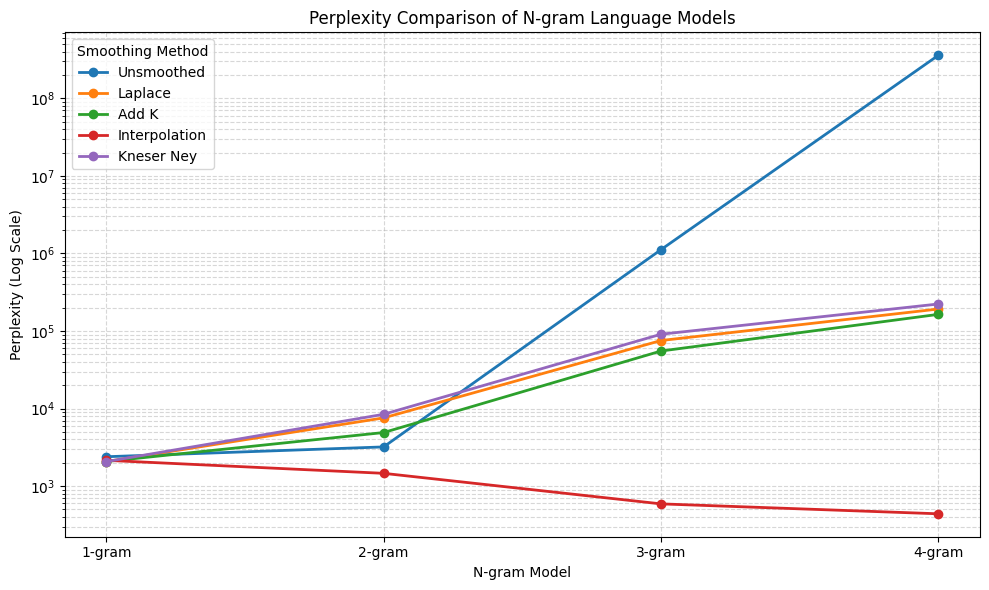

In [28]:
# %% [code]
import matplotlib.pyplot as plt

plot_df = perplexity_df.set_index("N-gram")

plt.figure(figsize=(10,6))

for column in plot_df.columns:
    plt.plot(
        plot_df.index,
        plot_df[column],
        marker='o',
        linewidth=2,
        label=column.replace("_"," ").title()
    )

plt.yscale("log")  # Logarithmic scale

plt.title("Perplexity Comparison of N-gram Language Models")
plt.xlabel("N-gram Model")
plt.ylabel("Perplexity (Log Scale)")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend(title="Smoothing Method")
plt.ylabel("Perplexity (Log Scale)")

plt.tight_layout()
plt.show()